### Business Problem Definition

**Information about the selected dataset**

Features are computed from a digitized image of a fine needle aspirate (FNA) of a breast mass.  They describe characteristics of the cell nuclei present in the image. A few of the images can be found at http://www.cs.wisc.edu/~street/images/

Separating plane described above was obtained using Multisurface Method-Tree (MSM-T) [K. P. Bennett, "Decision Tree Construction Via Linear Programming." Proceedings of the 4th Midwest Artificial Intelligence and Cognitive Science Society, pp. 97-101, 1992], a classification method which uses linear programming to construct a decision tree.  Relevant features were selected using an exhaustive search in the space of 1-4 features and 1-3 separating planes.

The actual linear program used to obtain the separating plane in the 3-dimensional space is that described in: [K. P. Bennett and O. L. Mangasarian: "Robust Linear Programming Discrimination of Two Linearly Inseparable Sets", Optimization Methods and Software 1, 1992, 23-34].


**Problem Definition and Motivation:**
* **Domain**: Health (Saúde)
* **Problem Type**: Supervised Machine Learning – Binary Classification
* **Target Variable ($Y$)**: Diagnosis (Malignant / Benign)

In the healthcare domain, early and accurate diagnosis of breast cancer is critical for improving patient survival rates and guiding timely medical interventions. Traditional diagnostic processes rely heavily on manual evaluation of cell nuclei characteristics, which can be time-consuming and subject to human variability.This project addresses a binary classification problem within supervised machine learning. The target variable ($Y$) is the diagnosis of a tumor, categorized as either Malignant (cancerous) or Benign (non-cancerous)8. The goal is to determine whether automated classification algorithms can reliably distinguish between malignant and benign cases based on digitized clinical features extracted from fine needle aspirate (FNA) images of breast masses.To ensure academic rigor and compliance with assessment standards, this study utilizes the real-world, publicly available Breast Cancer Wisconsin (Diagnostic) Dataset sourced from the UCI Machine Learning Repository. After cleaning, the dataset consists of **569** instances and **30** numerical features (such as radius, texture, perimeter, area, and smoothness of cell nuclei).

**Objective:**

* **Data Pre-processing and Feature Scaling:** Clean the dataset, handle categorical target encoding (`Malignant` \= 1, `Benign` \= 0), and apply standardization (`StandardScaler`) to features to optimize distance-based algorithms like kNN

* **Model Development:** Implement at least two distinct supervised classification algorithms (**[xgboost](https://xgboost.readthedocs.io/en/stable/get_started.html)** and **[Random Forest](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html)**)

* **Multi-Split Performance Evaluation:** Evaluate the variation in model accuracy across three distinct training set sizes (**5%**, **15%**, and **25%**) using **Cross-Validation** techniques to analyze how restricted training data impacts model learning and stability

* **Hyperparameter Optimization**: Apply `GridSearchCV` on one selected training data split to systematically tune key hyperparameters (e.g., shuffle, colsample_bylevel for xgboost / tree depth for Random Forest)


* **Comprehensive Metric Assessment:** Evaluate predictions using a full suite of classification metrics, including **Accuracy**, **Precision**, **Recall (Sensitivity)**, **F1-Score**, and **Confusion Matrix**. In a medical diagnostic context, particular emphasis is placed on maximizing **Recall** to minimize critical False Negatives

* **Comparative Analysis &amp; Generalization:** Interpret model outcomes, discuss trade-offs regarding **overfitting**, **underfitting**, and model generalizability.


**Expected Benefits:**
* **Efficiency:** Reduce the time and cost of feedback analysis.
* **Rapid Decision-Making:** Enable medical teams to quickly identify whether the cancer is malignant or benign and decide on the best type of treatment for the patient.
* **Prioritization:** Forward the result to the medical team as a priority, improving the chances of curing or reducing the cancer.

### Importing Packages
This is the workspace preparation phase. Here, we load all the necessary Python tools and libraries (such as Pandas for data manipulation, Scikit-learn for modeling, and Matplotlib/Seaborn for visualizations) that will be used throughout the project.

In [1]:
import logging
import pandas as pd
import numpy as np
import seaborn as sns
from pathlib import Path
from typing import List, Dict
import matplotlib.pyplot as plt
from ucimlrepo import fetch_ucirepo
from sklearn.metrics import confusion_matrix, classification_report

In [2]:
logging.basicConfig(
    format=("%(asctime)s | %(levelname)s | File_name ~> %(module)s.py "
            "| Function ~> %(funcName)s | Line ~~> %(lineno)d  ~~>  %(message)s"),
    level=logging.INFO
)

In [3]:
# Display settings
sns.set_style('whitegrid')
%matplotlib inline

In [4]:
%reload_ext watermark
%watermark --author "Matheus DoS S. Silva"
%watermark --email "2026438@student.cct.ie"
%watermark --github_username "MattheuSxS"
%watermark --date
%watermark --python
%watermark --iversions

Author: Matheus DoS S. Silva

Email: 2026438@student.cct.ie

Github username: MattheuSxS

Date: 2026-10-04

Python implementation: CPython
Python version       : 3.14.7
IPython version      : 9.17.1

logging   : 0.5.1.2
matplotlib: 3.11.2
numpy     : 2.5.3
pandas    : 3.0.6
seaborn   : 0.13.2
sklearn   : 1.9.1
ucimlrepo : 0.0.7



### Loading and Understanding the Data

This is the first encounter with the project's raw material. We load the data from a source (in our case, a CSV file) into a Pandas DataFrame and perform an initial check to understand its structure.

In [5]:
def download_dataset() -> pd.DataFrame:
    data_dir = Path("../data")
    dataset_file = data_dir / "data.csv"

    data_dir.mkdir(parents=True, exist_ok=True)

    try:
        if not dataset_file.exists():

            logging.warning("📥 Dataset not found. Downloading from UC Irvine Machine Learning Repository...")

            try:
                data_dict = fetch_ucirepo(id=17) 
                df = data_dict["data"]["features"]
                df["Diagnosis"] = data_dict["data"]["targets"]

                return df

            except Exception as e:
                return pd.read_csv("https://archive.ics.uci.edu/static/public/17/data.csv")
                
        else:
            logging.info(f"✅ Dataset already exists: {dataset_file}")

        return  pd.read_csv(dataset_file, sep=",")

    except Exception as e:
        logging.error(f"❌ Failed to download or read the dataset: {e}")

In [6]:
df = download_dataset()

2026-10-04 12:27:53,072 | INFO | File_name ~> 2560165815.py | Function ~> download_dataset | Line ~~> 23  ~~>  ✅ Dataset already exists: ../data/data.csv


In [7]:
# logging.info(f" Shape of DataSet Breast Cancer Wisconsin: {df.shape}")
print(f" Shape of DataSet Breast Cancer Wisconsin: {df.shape}")

 Shape of DataSet Breast Cancer Wisconsin: (569, 32)


In [8]:
df.head()

,ID,radius1,texture1,perimeter1,area1,smoothness1,compactness1,concavity1,concave_points1,symmetry1,...,texture3,perimeter3,area3,smoothness3,compactness3,concavity3,concave_points3,symmetry3,fractal_dimension3,Diagnosis
0,842302,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,M
1,842517,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,M
2,84300903,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,M
3,84348301,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,M
4,84358402,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,M


In [9]:
df.sample(3)

,ID,radius1,texture1,perimeter1,area1,smoothness1,compactness1,concavity1,concave_points1,symmetry1,...,texture3,perimeter3,area3,smoothness3,compactness3,concavity3,concave_points3,symmetry3,fractal_dimension3,Diagnosis
299,892399,10.510,23.09,66.85,334.2,0.10150,0.06797,0.02495,0.01875,0.1695,...,24.22,70.10,362.7,0.1143,0.08614,0.04158,0.03125,0.2227,0.06777,B
21,8510824,9.504,12.44,60.34,273.9,0.10240,0.06492,0.02956,0.02076,0.1815,...,15.66,65.13,314.9,0.1324,0.11480,0.08867,0.06227,0.2450,0.07773,B
340,89813,14.420,16.54,94.15,641.2,0.09751,0.11390,0.08007,0.04223,0.1912,...,21.51,111.40,862.1,0.1294,0.33710,0.37550,0.14140,0.3053,0.08764,B


In [10]:
df.tail(5)

,ID,radius1,texture1,perimeter1,area1,smoothness1,compactness1,concavity1,concave_points1,symmetry1,...,texture3,perimeter3,area3,smoothness3,compactness3,concavity3,concave_points3,symmetry3,fractal_dimension3,Diagnosis
564,926424,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,...,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115,M
565,926682,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,...,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637,M
566,926954,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,...,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820,M
567,927241,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,0.2397,...,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400,M
568,92751,7.76,24.54,47.92,181.0,0.05263,0.04362,0.00000,0.00000,0.1587,...,30.37,59.16,268.6,0.08996,0.06444,0.0000,0.0000,0.2871,0.07039,B


### Exploratory Data Analysis (EDA)

The investigation phase. Here, we "dive" into the data to uncover patterns, anomalies, and insights. We use charts (such as counts of positive vs. negative sentiment) and statistics to understand the data's distribution and characteristics before making any modifications.

In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 32 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   ID                  569 non-null    int64  
 1   radius1             569 non-null    float64
 2   texture1            569 non-null    float64
 3   perimeter1          569 non-null    float64
 4   area1               569 non-null    float64
 5   smoothness1         569 non-null    float64
 6   compactness1        569 non-null    float64
 7   concavity1          569 non-null    float64
 8   concave_points1     569 non-null    float64
 9   symmetry1           569 non-null    float64
 10  fractal_dimension1  569 non-null    float64
 11  radius2             569 non-null    float64
 12  texture2            569 non-null    float64
 13  perimeter2          569 non-null    float64
 14  area2               569 non-null    float64
 15  smoothness2         569 non-null    float64
 16  compactness2       

In [12]:
df.describe()

,ID,radius1,texture1,perimeter1,area1,smoothness1,compactness1,concavity1,concave_points1,symmetry1,...,radius3,texture3,perimeter3,area3,smoothness3,compactness3,concavity3,concave_points3,symmetry3,fractal_dimension3
count,5.690000e+02,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,3.037183e+07,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,...,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,1.250206e+08,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,...,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,8.670000e+03,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,...,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,8.692180e+05,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,...,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,9.060240e+05,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,...,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,8.813129e+06,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,...,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,9.113205e+08,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,...,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


In [13]:
# Check for null fields
null_columns = []
for column, value in zip(df.columns, df.isnull().sum()):
    if value > 0:
        logging.warning(f"There are ~~> {value} <~~ null values in the **{column}** column")
        null_columns.append(column)

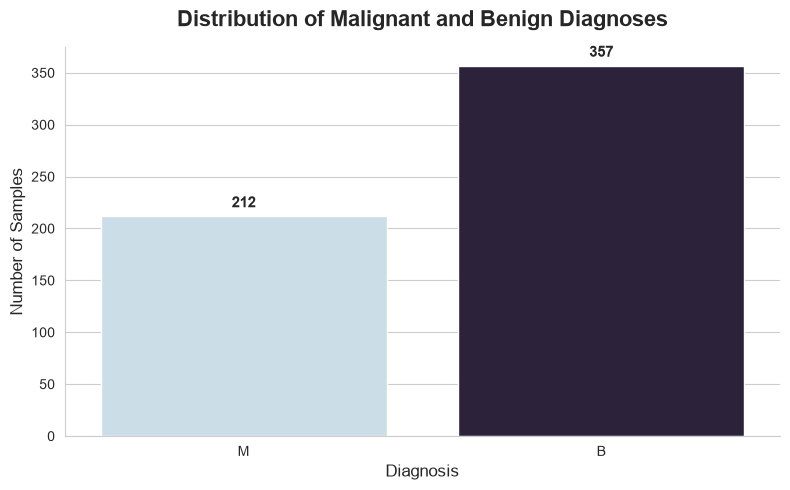

In [19]:
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    x = "Diagnosis",
    data = df,
    hue = "Diagnosis",
    palette = "ch:s=.25,rot=-.25",
    legend = False
)

plt.title(
    "Distribution of Malignant and Benign Diagnoses",
    fontsize = 16,
    fontweight = "bold",
    pad = 15
)

plt.xlabel("Diagnosis", fontsize=12)
plt.ylabel("Number of Samples", fontsize=12)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt = "%d",
        padding = 4,
        fontsize = 11,
        fontweight = "bold"
    )

sns.despine()
plt.tight_layout()
plt.show()

**The beginning of everything**

Correlation analysis was initially used to identify relationships between features and the target variable and to detect highly correlated features. Feature selection was then performed to reduce redundancy and identify the most relevant predictors.

In [ ]:
df_breast_cancer  = df.select_dtypes(include=['float64', 'int64'])

correlation_matrix = df_breast_cancer.corr()

plt.figure(figsize = (20, 20))
sns.heatmap(correlation_matrix, annot = True, fmt = '.2f', cmap = 'coolwarm', square = True, cbar_kws = {"shrink": .8})
plt.title('Heatmap of Correlation Matrix for Breast Cancer Wisconsin Dataset')

plt.show()

**Create a list of all columns with a ratio above 55% relative to the Diagnosis column.**

In [ ]:
correlation = df.corr(numeric_only=True)

corr_list = []

for column, value in zip(
    correlation.columns,
    correlation["Diagnosis"].sort_values(ascending=False)
):
    if value >= 0.55 and column not in ["ID", "Diagnosis"]:
        corr_list.append(column)

### Data Cleaning and Transformation

In this step, we correct the issues identified during EDA. This includes handling missing values ​​(for example, by removing the corresponding rows), ensuring the data is in the correct format, and applying the function.

In [ ]:
df['Diagnosis'] = df['Diagnosis'].replace({"M": 1, "B": 0}).astype(np.int64)

In [ ]:
X = df.loc[:, ~df.columns.isin(['ID','Diagnosis'])]
y = df['Diagnosis']

In [ ]:
df['Diagnosis']

In [ ]:
df.info()

In [ ]:
corr_list

### Splitting into Training and Test Data

An essential step for model training and evaluation. We split the dataset into two parts: a larger one (training), which the model uses to learn, and a smaller one (test), which is kept "hidden" from the model to simulate new data and evaluate its actual performance after training.

**As stated in the document, the data needs to be split into the following formats [ 5%, 15%, and 25% ], so we will use a function to avoid code duplication.**

In [ ]:
def splittint_data(data:pd.DataFrame, label:pd.DataFrame, _test_size:float = 0.30, _random_state:int = 1):
    print(\
        f"""
             X.shape, y.shape, X_train.shape, X_test.shape, y_train.shape, y_test.shape
        """)
    return train_test_split(data, label, test_size = _test_size, random_state = _random_state)

### Predictive Modeling Pipeline

Here, we build an automated production pipeline for our model. The Scikit-learn Pipeline encapsulates all preprocessing stepS and the final model (Supervised Classification Models), ensuring that the same steps are consistently applied to both the training data and new data.


**Initially, we will use the three models below.**

* [Random Forest](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html)
* [Xgboost](https://xgboost.readthedocs.io/en/stable/parameter.html)

#### Building Decision Tree Model

In [ ]:
from sklearn.tree import DecisionTreeClassifier

In [ ]:
# clf = DecisionTreeClassifier(criterion='gini', max_depth = 4, random_state = 0)

# # Train Decision Tree Classifer
# clf = clf.fit(X_train, y_train)

# #Predict the response for test dataset
# y_pred = clf.predict(X_test)

In [ ]:
# # Model Accuracy, how often is the classifier correct?
# print("Accuracy:",metrics.accuracy_score(y_test, y_pred))

# # Rounded upto 2 decimal places
# print( "Accuracy: {:.2f}".format(metrics.accuracy_score(y_test, y_pred)) )

In [ ]:
# # Predict by using an object classifier 'clf'
# y_predict = clf.predict(X_test)

# # Calculate cm by using a method named as 'confusion_matrix'
# cm = confusion_matrix(y_test, y_predict)

# # Plot confusion matrix with integers using seaborn heatmap
# plt.figure(figsize=(6, 4))
# sns.heatmap(cm, annot=True, fmt='d')  # 'd' stands for integer format
# plt.xlabel('Predicted labels')
# plt.ylabel('True labels')
# plt.title('Confusion Matrix')
# plt.show()

# # Generate classification report
# report = classification_report(y_test, y_predict)
# print("Classification Report:")
# print(report)

In [ ]:
# **3 Splits de Treino (5%, 15% e 25%):**

In [ ]:
# from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

# # Confusion Matrix
# cm = confusion_matrix(y_test, y_pred)
# disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Class 0", "Class 1"])
# disp.plot(cmap="Blues")
# plt.title(f"Confusion Matrix (k={best_k})")
# plt.grid(False)
# plt.show()

# # Detailed classification report
# print("Classification Report:")
# print(classification_report(y_test, y_pred, target_names=["Class 0", "Class 1"]))

#### Building Random Forest Model

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.datasets import make_classification

In [ ]:
from sklearn.ensemble import RandomForestClassifier

X, y = make_classification(
    n_samples = 1000,
    n_features = 4,
    n_informative = 2,
    n_redundant = 0,
    random_state = 0,
    shuffle = False
)

clf = RandomForestClassifier(max_depth=2, random_state=0)
clf.fit(X, y)

clf.predict([[0, 0, 0, 0]])

#### Building Xgboost Model

### Model Evaluation and Metric Interpretation